In [1]:
!pip install google-api-python-client pandas matplotlib seaborn

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from googleapiclient.discovery import build

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from getpass import getpass

API_KEY = getpass("Enter your YouTube API Key: ")

youtube = build(
    "youtube",
    "v3",
    developerKey=API_KEY
)

print("YouTube API connected successfully!")

Enter your YouTube API Key: ··········
YouTube API connected successfully!


In [4]:
request = youtube.search().list(
    part="snippet",
    q="Chhaava official trailer",
    type="video",
    maxResults=5
)

response = request.execute()

for item in response["items"]:
    print("Title:", item["snippet"]["title"])
    print("Video ID:", item["id"]["videoId"])
    print("-" * 50)

Title: Chhaava | Official Trailer | Vicky Kaushal, Rashmika Mandanna, Akshaye Khanna | Netflix India
Video ID: hs3w32RG8L8
--------------------------------------------------
Title: Chhaava Teaser | Vicky Kaushal | Rashmika M | Akshaye K | Dinesh V | Laxman U | 14th Feb 2025
Video ID: nsC5PhXS19Y
--------------------------------------------------
Title: Chhaava | Official Trailer | Vicky K | Rashmika M | Akshaye K | Dinesh Vijan | Laxman U | 14th Feb
Video ID: 77vRyWNqZjM
--------------------------------------------------
Title: Chakkven (Official Trailer) | Kartar Cheema | Vishal Brar | New Punjabi Movie | In Cinemas 20th Nov
Video ID: O5ipZ4dXFIc
--------------------------------------------------
Title: Chakkven | Official Teaser | Kartar Cheema | Vishal Brar | New Punjabi Movie | In Cinemas 20th NOV.
Video ID: Vi1-bmCN5OA
--------------------------------------------------


In [5]:
video_ids = [
    "hs3w32RG8L8",
    "nsC5PhXS19Y",
    "77vRyWNqZjM"
]

request = youtube.videos().list(
    part="snippet,statistics",
    id=",".join(video_ids)
)

response = request.execute()

for video in response["items"]:
    print("Title:", video["snippet"]["title"])
    print("Channel:", video["snippet"]["channelTitle"])
    print("Published:", video["snippet"]["publishedAt"])
    print("Views:", video["statistics"].get("viewCount", 0))
    print("Likes:", video["statistics"].get("likeCount", 0))
    print("Comments:", video["statistics"].get("commentCount", 0))
    print("-" * 60)

Title: Chhaava | Official Trailer | Vicky Kaushal, Rashmika Mandanna, Akshaye Khanna | Netflix India
Channel: Netflix India
Published: 2025-04-10T05:30:00Z
Views: 2458894
Likes: 23907
Comments: 980
------------------------------------------------------------
Title: Chhaava Teaser | Vicky Kaushal | Rashmika M | Akshaye K | Dinesh V | Laxman U | 14th Feb 2025
Channel: Maddock Films
Published: 2024-08-19T05:29:33Z
Views: 31794907
Likes: 505734
Comments: 23876
------------------------------------------------------------
Title: Chhaava | Official Trailer | Vicky K | Rashmika M | Akshaye K | Dinesh Vijan | Laxman U | 14th Feb
Channel: Maddock Films
Published: 2025-01-22T11:45:04Z
Views: 81728339
Likes: 1238354
Comments: 96159
------------------------------------------------------------


In [6]:
import pandas as pd
from datetime import datetime, timezone

selected_video_id = "77vRyWNqZjM"

request = youtube.videos().list(
    part="snippet,statistics",
    id=selected_video_id
)

response = request.execute()

video = response["items"][0]

chhaava_data = {
    "movie_name": "Chhaava",
    "language": "Hindi",
    "release_date": "2025-02-14",
    "video_title": video["snippet"]["title"],
    "channel": video["snippet"]["channelTitle"],
    "video_id": selected_video_id,
    "published_date": video["snippet"]["publishedAt"],
    "views": int(video["statistics"].get("viewCount", 0)),
    "likes": int(video["statistics"].get("likeCount", 0)),
    "comments": int(video["statistics"].get("commentCount", 0)),
    "retrieved_at": datetime.now(timezone.utc).isoformat()
}

df = pd.DataFrame([chhaava_data])

df.to_csv("chhaava_youtube_data.csv", index=False)

display(df)

print("Chhaava dataset saved successfully!")

,movie_name,language,release_date,video_title,channel,video_id,published_date,views,likes,comments,retrieved_at
0,Chhaava,Hindi,2025-02-14,Chhaava | Official Trailer | Vicky K | Rashmik...,Maddock Films,77vRyWNqZjM,2025-01-22T11:45:04Z,81728339,1238354,96159,2026-11-26T09:59:08.636040+00:00


Chhaava dataset saved successfully!


In [7]:
comments_request = youtube.commentThreads().list(
    part="snippet",
    videoId=selected_video_id,
    maxResults=100,
    textFormat="plainText",
    order="relevance"
)

comments_response = comments_request.execute()

comments_data = []

for item in comments_response["items"]:
    comment = item["snippet"]["topLevelComment"]["snippet"]

    comments_data.append({
        "movie_name": "Chhaava",
        "comment": comment["textDisplay"],
        "published_at": comment["publishedAt"],
        "likes": comment["likeCount"]
    })

comments_df = pd.DataFrame(comments_data)

comments_df.to_csv(
    "chhaava_comments.csv",
    index=False
)

print("Total comments collected:", len(comments_df))

display(comments_df.head(10))

Total comments collected: 100


,movie_name,comment,published_at,likes
0,Chhaava,CHHAAVA : He created River of Blood 🩸🩸\r\nMAHA...,2026-09-24T16:35:38Z,221
1,Chhaava,"Chhaavaa , Dhurandhar best movie role Akshay k...",2025-12-13T20:28:27Z,531
2,Chhaava,1:25 goosebumps. Can't believe that's Akshay K...,2025-01-22T18:59:58Z,95
3,Chhaava,Who is here after DHURANDHAR 🥵\n\nRehman dakai...,2025-12-10T09:02:34Z,548
4,Chhaava,Outstanding Acting By Vicky K Sir And Rehman S...,2025-01-22T16:45:07Z,31187
5,Chhaava,हे हिंदवी स्वराज्य व्हावे ही श्रींची इच्छा 🔥🔥,2025-01-23T07:31:54Z,34267
6,Chhaava,Who is here after Raja shivaji teaser ❤😂,2026-03-31T14:44:50Z,974
7,Chhaava,Ritesh deshmukh ki movie Raja Shivaji ka tease...,2026-03-31T15:59:20Z,140
8,Chhaava,Akshay Khanna Acting. 🤫💥,2025-12-09T04:59:24Z,95
9,Chhaava,"Movie released an year ago, but still Watching...",2026-02-15T16:32:11Z,61


In [8]:
# Convert comment dates into datetime format
comments_df["published_at"] = pd.to_datetime(
    comments_df["published_at"],
    utc=True
)

# Define movie release date
release_date = pd.Timestamp("2025-02-14", tz="UTC")

# Categorise comments
comments_df["comment_type"] = comments_df["published_at"].apply(
    lambda x: "Pre-release" if x < release_date else "Post-release"
)

# Count comments in each category
print(comments_df["comment_type"].value_counts())

# Save updated dataset
comments_df.to_csv("chhaava_comments.csv", index=False)

display(comments_df.head(10))

comment_type
Pre-release     66
Post-release    34
Name: count, dtype: int64


,movie_name,comment,published_at,likes,comment_type
0,Chhaava,CHHAAVA : He created River of Blood 🩸🩸\r\nMAHA...,2026-09-24 16:35:38+00:00,221,Post-release
1,Chhaava,"Chhaavaa , Dhurandhar best movie role Akshay k...",2025-12-13 20:28:27+00:00,531,Post-release
2,Chhaava,1:25 goosebumps. Can't believe that's Akshay K...,2025-01-22 18:59:58+00:00,95,Pre-release
3,Chhaava,Who is here after DHURANDHAR 🥵\n\nRehman dakai...,2025-12-10 09:02:34+00:00,548,Post-release
4,Chhaava,Outstanding Acting By Vicky K Sir And Rehman S...,2025-01-22 16:45:07+00:00,31187,Pre-release
5,Chhaava,हे हिंदवी स्वराज्य व्हावे ही श्रींची इच्छा 🔥🔥,2025-01-23 07:31:54+00:00,34267,Pre-release
6,Chhaava,Who is here after Raja shivaji teaser ❤😂,2026-03-31 14:44:50+00:00,974,Post-release
7,Chhaava,Ritesh deshmukh ki movie Raja Shivaji ka tease...,2026-03-31 15:59:20+00:00,140,Post-release
8,Chhaava,Akshay Khanna Acting. 🤫💥,2025-12-09 04:59:24+00:00,95,Post-release
9,Chhaava,"Movie released an year ago, but still Watching...",2026-02-15 16:32:11+00:00,61,Post-release


In [9]:
movies = {
    "Saiyaara": "Saiyaara official trailer YRF",
    "Housefull 5": "Housefull 5 official trailer",
    "Dhurandhar": "Dhurandhar official trailer",
    "Kantara Chapter 1": "Kantara Chapter 1 official trailer Hombale",
    "Coolie": "Coolie official trailer Sun Pictures",
    "They Call Him OG": "They Call Him OG official trailer",
    "Lokah Chapter 1": "Lokah Chapter 1 Chandra official trailer"
}

for movie, query in movies.items():

    print("\nMOVIE:", movie)

    request = youtube.search().list(
        part="snippet",
        q=query,
        type="video",
        maxResults=5
    )

    response = request.execute()

    for item in response["items"]:
        print("Title:", item["snippet"]["title"])
        print("Channel:", item["snippet"]["channelTitle"])
        print("Video ID:", item["id"]["videoId"])
        print("-" * 50)


MOVIE: Saiyaara
Title: Saiyaara | Official Trailer | Ahaan Panday | Aneet Padda | Mohit Suri
Channel: YRF
Video ID: 9r-tT5IN0vg
--------------------------------------------------
Title: Saiyaara | Official Teaser | Ahaan Panday | Aneet Padda | Mohit Suri
Channel: YRF
Video ID: nF31d_f4n_A
--------------------------------------------------
Title: Saiyaara | Official Trailer | Ahaan Panday, Aneet Padda | Mohit Suri | Netflix India
Channel: Netflix India
Video ID: GagxSlo253M
--------------------------------------------------
Title: Saiyaara Title Song | Ahaan Panday, Aneet Padda | Tanishk Bagchi, Faheem A, Arslan N | Irshad Kamil
Channel: YRF
Video ID: BSJa1UytM8w
--------------------------------------------------
Title: Saiyaara Full Song | Ahaan Panday, Aneet Padda | Tanishk Bagchi, Faheem A, Arslan N | Irshad Kamil
Channel: YRF
Video ID: MQoColHyGzQ
--------------------------------------------------

MOVIE: Housefull 5
Title: Housefull 5 (full movie) | Akshay Kumar| Ritesh Deshmuk | 

In [10]:

movies = {
    "Saiyaara": "Saiyaara official theatrical trailer YRF",
    "Housefull 5": "Housefull 5 official trailer Nadiadwala Grandson",
    "Dhurandhar": "Dhurandhar official theatrical trailer Jio Studios",
    "Kantara Chapter 1": "Kantara Chapter 1 official theatrical trailer Hombale Films",
    "Coolie": "Coolie official theatrical trailer Sun Pictures Rajinikanth",
    "They Call Him OG": "They Call Him OG official trailer DVV Entertainment",
    "Lokah Chapter 1": "Lokah Chapter 1 Chandra official trailer Wayfarer Films"
}

for movie, query in movies.items():

    print("\n" + "=" * 70)
    print("MOVIE:", movie)
    print("=" * 70)

    request = youtube.search().list(
        part="snippet",
        q=query,
        type="video",
        maxResults=10
    )

    response = request.execute()

    for i, item in enumerate(response["items"], 1):

        print("\nResult:", i)
        print("Title:", item["snippet"]["title"])
        print("Channel:", item["snippet"]["channelTitle"])
        print("Video ID:", item["id"]["videoId"])
        print("Published:", item["snippet"]["publishedAt"])



MOVIE: Saiyaara

Result: 1
Title: Saiyaara | Official Trailer | Ahaan Panday | Aneet Padda | Mohit Suri
Channel: YRF
Video ID: 9r-tT5IN0vg
Published: 2025-07-08T05:30:04Z

Result: 2
Title: Saiyaara | Official Teaser | Ahaan Panday | Aneet Padda | Mohit Suri
Channel: YRF
Video ID: nF31d_f4n_A
Published: 2025-05-30T05:30:05Z

Result: 3
Title: Saiyaara Title Song | Ahaan Panday, Aneet Padda | Tanishk Bagchi, Faheem A, Arslan N | Irshad Kamil
Channel: YRF
Video ID: BSJa1UytM8w
Published: 2025-06-03T05:30:10Z

Result: 4
Title: Saiyaara | Deleted Scene 1 | Ahaan Panday, Aneet Padda | Mohit Suri
Channel: YRF
Video ID: xgZ5aZ0ifgA
Published: 2026-07-18T13:30:25Z

Result: 5
Title: Saiyaara Full Song | Ahaan Panday, Aneet Padda | Tanishk Bagchi, Faheem A, Arslan N | Irshad Kamil
Channel: YRF
Video ID: MQoColHyGzQ
Published: 2025-09-05T07:00:06Z

Result: 6
Title: Saiyaara Title Song | Ahaan Panday, Aneet Padda | Tanishk Bagchi, Faheem A, Arslan N | Irshad Kamil
Channel: ziddi_nawabzaada
Video ID

In [11]:

import pandas as pd
from datetime import datetime, timezone

# Movie details
movie_details = {
    "Saiyaara": {
        "query": "Saiyaara official theatrical trailer YRF",
        "language": "Hindi",
        "release_date": "2025-07-18",
        "channel": "YRF"
    },
    "Housefull 5": {
        "query": "Housefull 5 official theatrical trailer",
        "language": "Hindi",
        "release_date": "2025-06-06",
        "channel": "Nadiadwala Grandson"
    },
    "Dhurandhar": {
        "query": "Dhurandhar official theatrical trailer",
        "language": "Hindi",
        "release_date": "2025-12-05",
        "channel": "Jio Studios"
    },
    "Kantara Chapter 1": {
        "query": "Kantara Chapter 1 official theatrical trailer",
        "language": "Kannada",
        "release_date": "2025-10-02",
        "channel": "Hombale"
    },
    "Coolie": {
        "query": "Coolie official theatrical trailer Rajinikanth",
        "language": "Tamil",
        "release_date": "2025-08-14",
        "channel": "Sun"
    },
    "They Call Him OG": {
        "query": "They Call Him OG official theatrical trailer",
        "language": "Telugu",
        "release_date": "2025-09-25",
        "channel": "DVV"
    },
    "Lokah Chapter 1: Chandra": {
        "query": "Lokah Chapter 1 Chandra official theatrical trailer",
        "language": "Malayalam",
        "release_date": "2025-08-28",
        "channel": "Wayfarer"
    }
}

# Words that indicate the video is not a theatrical trailer
excluded_words = [
    "teaser", "song", "lyrical", "full movie",
    "glimpse", "making", "interview", "review"
]

results = []

for movie, details in movie_details.items():

    print("\nSearching:", movie)

    search_response = youtube.search().list(
        part="snippet",
        q=details["query"],
        type="video",
        maxResults=10
    ).execute()

    candidates = []

    for item in search_response["items"]:

        title = item["snippet"]["title"].lower()
        channel = item["snippet"]["channelTitle"].lower()

        if "trailer" not in title:
            continue

        if any(word in title for word in excluded_words):
            continue

        if details["channel"].lower() not in channel:
            continue

        candidates.append(item)

    if not candidates:
        print("No suitable trailer found. Skipping:", movie)
        continue

    # Select the first matching official-channel candidate
    selected = candidates[0]

    video_id = selected["id"]["videoId"]

    # Retrieve video statistics
    video_response = youtube.videos().list(
        part="snippet,statistics",
        id=video_id
    ).execute()

    if not video_response["items"]:
        print("Statistics unavailable:", movie)
        continue

    video = video_response["items"][0]
    stats = video["statistics"]

    row = {
        "Movie name": movie,
        "Language": details["language"],
        "Release date": details["release_date"],
        "Video title": video["snippet"]["title"],
        "Channel": video["snippet"]["channelTitle"],
        "Video ID": video_id,
        "Published date": video["snippet"]["publishedAt"],
        "Views": int(stats.get("viewCount", 0)),
        "Likes": int(stats.get("likeCount", 0)),
        "Comments": int(stats.get("commentCount", 0)),
        "Retrieval timestamp": datetime.now(timezone.utc).isoformat()
    }

    results.append(row)

    print("Selected:", row["Video title"])
    print("Channel:", row["Channel"])
    print("Video ID:", video_id)
    print("Views:", row["Views"])
    print("Likes:", row["Likes"])
    print("Comments:", row["Comments"])

# Create and save CSV
if results:

    df = pd.DataFrame(results)

    df.to_csv(
        "remaining_movies_youtube_data.csv",
        index=False
    )

    print("\n" + "=" * 50)
    print("DATA COLLECTION COMPLETED")
    print("=" * 50)

    display(df)

    print("\nCSV file saved successfully!")

    from google.colab import files
    files.download("remaining_movies_youtube_data.csv")

else:
    print("No data collected. Please check the search results.")



Searching: Saiyaara
Selected: Saiyaara | Official Trailer | Ahaan Panday | Aneet Padda | Mohit Suri
Channel: YRF
Video ID: 9r-tT5IN0vg
Views: 81394643
Likes: 801882
Comments: 31615

Searching: Housefull 5
No suitable trailer found. Skipping: Housefull 5

Searching: Dhurandhar
No suitable trailer found. Skipping: Dhurandhar

Searching: Kantara Chapter 1
Selected: Kantara Chapter 1 Trailer - Telugu | Rishab Shetty | Rukmini | Vijay Kiragandur | Hombale Films
Channel: Hombale Films
Video ID: axBF-4nNZ3s
Views: 18605843
Likes: 337009
Comments: 4768

Searching: Coolie
Selected: Coolie - Official Trailer | Superstar Rajinikanth | Sun Pictures | Lokesh | Anirudh
Channel: Sun TV
Video ID: qeVfT2iLiu0
Views: 29543836
Likes: 839541
Comments: 33903

Searching: They Call Him OG
Selected: They Call Him OG Trailer - Pawan Kalyan | Emraan Hashmi | Sujeeth | Thaman S | DVV Danayya |
Channel: DVV Entertainment
Video ID: _8J8LwoVH_0
Views: 18054008
Likes: 743992
Comments: 28845

Searching: Lokah Chapte

,Movie name,Language,Release date,Video title,Channel,Video ID,Published date,Views,Likes,Comments,Retrieval timestamp
0,Saiyaara,Hindi,2025-07-18,Saiyaara | Official Trailer | Ahaan Panday | A...,YRF,9r-tT5IN0vg,2025-07-08T05:30:04Z,81394643,801882,31615,2026-11-26T10:18:55.572639+00:00
1,Kantara Chapter 1,Kannada,2025-10-02,Kantara Chapter 1 Trailer - Telugu | Rishab Sh...,Hombale Films,axBF-4nNZ3s,2025-09-22T07:15:10Z,18605843,337009,4768,2026-11-26T10:18:56.430595+00:00
2,Coolie,Tamil,2025-08-14,Coolie - Official Trailer | Superstar Rajinika...,Sun TV,qeVfT2iLiu0,2025-08-02T13:30:25Z,29543836,839541,33903,2026-11-26T10:18:56.789677+00:00
3,They Call Him OG,Telugu,2025-09-25,They Call Him OG Trailer - Pawan Kalyan | Emra...,DVV Entertainment,_8J8LwoVH_0,2025-09-22T08:55:04Z,18054008,743992,28845,2026-11-26T10:18:57.101096+00:00
4,Lokah Chapter 1: Chandra,Malayalam,2025-08-28,Lokah Chapter 1: Chandra | Official Trailer | ...,Wayfarer Films Music,64XHtNWTB5o,2025-08-24T14:08:06Z,16311601,198578,6321,2026-11-26T10:18:57.422145+00:00



CSV file saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# Collect missing movies and verify Kannada Kantara trailer

extra_movies = {
    "Housefull 5": {
        "query": "Housefull 5 official theatrical trailer",
        "language": "Hindi",
        "release_date": "2025-06-06",
        "channel": "nadiadwalagrandson"
    },
    "Dhurandhar": {
        "query": "Dhurandhar official theatrical trailer Jio Studios",
        "language": "Hindi",
        "release_date": "2025-12-05",
        "channel": "jiostudios"
    },
    "Kantara Chapter 1": {
        "query": "Kantara Chapter 1 official Kannada theatrical trailer",
        "language": "Kannada",
        "release_date": "2025-10-02",
        "channel": "hombale"
    }
}

for movie, details in extra_movies.items():

    print("\nSearching:", movie)

    response = youtube.search().list(
        part="snippet",
        q=details["query"],
        type="video",
        maxResults=10
    ).execute()

    selected = None

    for item in response["items"]:

        title = item["snippet"]["title"].lower()
        channel = item["snippet"]["channelTitle"].lower()

        clean_channel = channel.replace(" ", "").replace("-", "")

        if "trailer" not in title:
            continue

        if any(word in title for word in [
            "teaser", "song", "full movie",
            "glimpse", "making", "review"
        ]):
            continue

        if details["channel"] not in clean_channel:
            continue

        if movie == "Kantara Chapter 1" and "kannada" not in title:
            continue

        selected = item
        break

    if selected is None:
        print("No matching trailer found. Needs manual verification.")
        continue

    video_id = selected["id"]["videoId"]

    video_response = youtube.videos().list(
        part="snippet,statistics",
        id=video_id
    ).execute()

    if not video_response["items"]:
        continue

    video = video_response["items"][0]
    stats = video["statistics"]

    row = {
        "Movie name": movie,
        "Language": details["language"],
        "Release date": details["release_date"],
        "Video title": video["snippet"]["title"],
        "Channel": video["snippet"]["channelTitle"],
        "Video ID": video_id,
        "Published date": video["snippet"]["publishedAt"],
        "Views": int(stats.get("viewCount", 0)),
        "Likes": int(stats.get("likeCount", 0)),
        "Comments": int(stats.get("commentCount", 0)),
        "Retrieval timestamp": datetime.now(timezone.utc).isoformat()
    }

    if movie == "Kantara Chapter 1":
        results[:] = [
            r for r in results
            if r["Movie name"] != movie
        ]

    results.append(row)

    print("Selected:", row["Video title"])
    print("Channel:", row["Channel"])
    print("Views:", row["Views"])

# Save updated dataset
df = pd.DataFrame(results)

df.to_csv("remaining_movies_youtube_data.csv", index=False)

display(df)

from google.colab import files
files.download("remaining_movies_youtube_data.csv")



Searching: Housefull 5
Selected: Housefull 5 | Official Trailer | Sajid Nadiadwala | Tarun Mansukhani | In Cinemas on 6th June 2025
Channel: NadiadwalaGrandson
Views: 33956584

Searching: Dhurandhar
Selected: Dhurandhar Official Trailer | Ranveer Singh | Aditya Dhar | Storming Cinemas Worldwide
Channel: JioStudios
Views: 101967499

Searching: Kantara Chapter 1
Selected: Kantara Chapter 1 Trailer - Kannada | Rishab Shetty | Rukmini | Vijay Kiragandur | Hombale Films
Channel: Hombale Films
Views: 23925371


,Movie name,Language,Release date,Video title,Channel,Video ID,Published date,Views,Likes,Comments,Retrieval timestamp
0,Saiyaara,Hindi,2025-07-18,Saiyaara | Official Trailer | Ahaan Panday | A...,YRF,9r-tT5IN0vg,2025-07-08T05:30:04Z,81394643,801882,31615,2026-11-26T10:18:55.572639+00:00
1,Coolie,Tamil,2025-08-14,Coolie - Official Trailer | Superstar Rajinika...,Sun TV,qeVfT2iLiu0,2025-08-02T13:30:25Z,29543836,839541,33903,2026-11-26T10:18:56.789677+00:00
2,They Call Him OG,Telugu,2025-09-25,They Call Him OG Trailer - Pawan Kalyan | Emra...,DVV Entertainment,_8J8LwoVH_0,2025-09-22T08:55:04Z,18054008,743992,28845,2026-11-26T10:18:57.101096+00:00
3,Lokah Chapter 1: Chandra,Malayalam,2025-08-28,Lokah Chapter 1: Chandra | Official Trailer | ...,Wayfarer Films Music,64XHtNWTB5o,2025-08-24T14:08:06Z,16311601,198578,6321,2026-11-26T10:18:57.422145+00:00
4,Housefull 5,Hindi,2025-06-06,Housefull 5 | Official Trailer | Sajid Nadiadw...,NadiadwalaGrandson,xGQuT1wm2qk,2025-05-27T08:07:45Z,33956584,606233,36706,2026-11-26T10:20:22.725157+00:00
5,Dhurandhar,Hindi,2025-12-05,Dhurandhar Official Trailer | Ranveer Singh | ...,JioStudios,BKOVzHcjEIo,2025-11-18T06:50:49Z,101967499,914967,52738,2026-11-26T10:20:23.054205+00:00
6,Kantara Chapter 1,Kannada,2025-10-02,Kantara Chapter 1 Trailer - Kannada | Rishab S...,Hombale Films,TMQUFhWm8C0,2025-09-22T07:14:06Z,23925371,797600,20869,2026-11-26T10:20:23.410060+00:00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

import pandas as pd
from datetime import datetime, timezone

all_comments = []

# Use the seven movies already collected in results
for movie_data in results:

    movie = movie_data["Movie name"]
    video_id = movie_data["Video ID"]
    release_date = pd.to_datetime(movie_data["Release date"]).date()

    print("\nCollecting comments for:", movie)

    comments_collected = 0
    next_page_token = None

    try:
        while comments_collected < 100:

            request = youtube.commentThreads().list(
                part="snippet",
                videoId=video_id,
                maxResults=min(100, 100 - comments_collected),
                order="relevance",
                textFormat="plainText",
                pageToken=next_page_token
            )

            response = request.execute()

            for item in response["items"]:

                comment = item["snippet"]["topLevelComment"]["snippet"]

                comment_date = pd.to_datetime(
                    comment["publishedAt"]
                ).date()

                if comment_date < release_date:
                    comment_type = "Pre-release"
                else:
                    comment_type = "Post-release"

                all_comments.append({
                    "Movie name": movie,
                    "Video ID": video_id,
                    "Comment text": comment["textDisplay"],
                    "Publication date": comment["publishedAt"],
                    "Comment likes": comment["likeCount"],
                    "Comment type": comment_type
                })

                comments_collected += 1

            next_page_token = response.get("nextPageToken")

            if not next_page_token:
                break

        print("Comments collected:", comments_collected)

    except Exception as e:
        print("Could not collect comments for", movie)
        print("Reason:", str(e))

# Save comments into CSV
comments_df = pd.DataFrame(all_comments)

comments_df.to_csv(
    "remaining_movies_comments.csv",
    index=False
)

print("\n===================================")
print("COMMENT COLLECTION COMPLETED")
print("===================================")

print("Total comments:", len(comments_df))

if not comments_df.empty:
    print("\nComments by movie:")
    display(
        comments_df.groupby(
            ["Movie name", "Comment type"]
        ).size().unstack(fill_value=0)
    )

    from google.colab import files
    files.download("remaining_movies_comments.csv")



Comments collected: 100

Comments collected: 100

Comments collected: 100

Comments collected: 100

Comments collected: 100

Comments collected: 100

Comments collected: 100

COMMENT COLLECTION COMPLETED
Total comments: 700

Comments by movie:


Comment type,Post-release,Pre-release
Movie name,,
Coolie,33,67
Dhurandhar,86,14
Housefull 5,24,76
Kantara Chapter 1,20,80
Lokah Chapter 1: Chandra,62,38
Saiyaara,42,58
They Call Him OG,37,63


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

import pandas as pd
import os
from google.colab import files

# Check whether Chhaava files exist
required_files = [
    "chhaava_youtube_data.csv",
    "chhaava_comments.csv"
]

missing_files = [
    f for f in required_files if not os.path.exists(f)
]

if missing_files:
    print("Please upload your two Chhaava CSV files:")
    uploaded = files.upload()

# Load Chhaava datasets
chhaava_data = pd.read_csv("chhaava_youtube_data.csv")
chhaava_comments = pd.read_csv("chhaava_comments.csv")

# Combine YouTube statistics
master_youtube = pd.concat(
    [chhaava_data, df],
    ignore_index=True
)

# Combine audience comments
master_comments = pd.concat(
    [chhaava_comments, comments_df],
    ignore_index=True
)

# Remove duplicate records if any
master_youtube = master_youtube.drop_duplicates(
    subset=["Movie name", "Video ID"]
)

master_comments = master_comments.drop_duplicates(
    subset=["Movie name", "Comment text", "Publication date"]
)

# Save master datasets
master_youtube.to_csv(
    "master_youtube_data.csv",
    index=False
)

master_comments.to_csv(
    "master_comments.csv",
    index=False
)

# Display results
print("MASTER YOUTUBE DATA")
print("Total movies:", master_youtube["Movie name"].nunique())
display(master_youtube)

print("\nMASTER COMMENTS DATA")
print("Total comments:", len(master_comments))

print("\nComments by movie:")
display(
    master_comments.groupby("Movie name").size()
)

# Download both files
files.download("master_youtube_data.csv")
files.download("master_comments.csv")


MASTER YOUTUBE DATA
Total movies: 7


,movie_name,language,release_date,video_title,channel,video_id,published_date,views,likes,comments,...,Language,Release date,Video title,Channel,Video ID,Published date,Views,Likes,Comments,Retrieval timestamp
0,Chhaava,Hindi,2025-02-14,Chhaava | Official Trailer | Vicky K | Rashmik...,Maddock Films,77vRyWNqZjM,2025-01-22T11:45:04Z,81728339.0,1238354.0,96159.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Hindi,2025-07-18,Saiyaara | Official Trailer | Ahaan Panday | A...,YRF,9r-tT5IN0vg,2025-07-08T05:30:04Z,81394643.0,801882.0,31615.0,2026-11-26T10:18:55.572639+00:00
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Tamil,2025-08-14,Coolie - Official Trailer | Superstar Rajinika...,Sun TV,qeVfT2iLiu0,2025-08-02T13:30:25Z,29543836.0,839541.0,33903.0,2026-11-26T10:18:56.789677+00:00
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Telugu,2025-09-25,They Call Him OG Trailer - Pawan Kalyan | Emra...,DVV Entertainment,_8J8LwoVH_0,2025-09-22T08:55:04Z,18054008.0,743992.0,28845.0,2026-11-26T10:18:57.101096+00:00
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Malayalam,2025-08-28,Lokah Chapter 1: Chandra | Official Trailer | ...,Wayfarer Films Music,64XHtNWTB5o,2025-08-24T14:08:06Z,16311601.0,198578.0,6321.0,2026-11-26T10:18:57.422145+00:00
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Hindi,2025-06-06,Housefull 5 | Official Trailer | Sajid Nadiadw...,NadiadwalaGrandson,xGQuT1wm2qk,2025-05-27T08:07:45Z,33956584.0,606233.0,36706.0,2026-11-26T10:20:22.725157+00:00
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Hindi,2025-12-05,Dhurandhar Official Trailer | Ranveer Singh | ...,JioStudios,BKOVzHcjEIo,2025-11-18T06:50:49Z,101967499.0,914967.0,52738.0,2026-11-26T10:20:23.054205+00:00
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Kannada,2025-10-02,Kantara Chapter 1 Trailer - Kannada | Rishab S...,Hombale Films,TMQUFhWm8C0,2025-09-22T07:14:06Z,23925371.0,797600.0,20869.0,2026-11-26T10:20:23.410060+00:00



MASTER COMMENTS DATA
Total comments: 701

Comments by movie:


,0
Movie name,
Coolie,100
Dhurandhar,100
Housefull 5,100
Kantara Chapter 1,100
Lokah Chapter 1: Chandra,100
Saiyaara,100
They Call Him OG,100


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

print("========== YOUTUBE DATA ==========")

print("\nChhaava columns:")
print(chhaava_data.columns.tolist())

print("\nRemaining movies columns:")
print(df.columns.tolist())

print("\nChhaava sample:")
display(chhaava_data.head(2))

print("\nRemaining movies sample:")
display(df.head(2))


print("\n========== COMMENTS DATA ==========")

print("\nChhaava comment columns:")
print(chhaava_comments.columns.tolist())

print("\nRemaining comment columns:")
print(comments_df.columns.tolist())

print("\nChhaava comments sample:")
display(chhaava_comments.head(3))

print("\nRemaining comments sample:")
display(comments_df.head(3))


========== YOUTUBE DATA ==========

Chhaava columns:
['movie_name', 'language', 'release_date', 'video_title', 'channel', 'video_id', 'published_date', 'views', 'likes', 'comments', 'retrieved_at']

Remaining movies columns:
['Movie name', 'Language', 'Release date', 'Video title', 'Channel', 'Video ID', 'Published date', 'Views', 'Likes', 'Comments', 'Retrieval timestamp']

Chhaava sample:


,movie_name,language,release_date,video_title,channel,video_id,published_date,views,likes,comments,retrieved_at
0,Chhaava,Hindi,2025-02-14,Chhaava | Official Trailer | Vicky K | Rashmik...,Maddock Films,77vRyWNqZjM,2025-01-22T11:45:04Z,81728339,1238354,96159,2026-11-26T09:59:08.636040+00:00



Remaining movies sample:


,Movie name,Language,Release date,Video title,Channel,Video ID,Published date,Views,Likes,Comments,Retrieval timestamp
0,Saiyaara,Hindi,2025-07-18,Saiyaara | Official Trailer | Ahaan Panday | A...,YRF,9r-tT5IN0vg,2025-07-08T05:30:04Z,81394643,801882,31615,2026-11-26T10:18:55.572639+00:00
1,Coolie,Tamil,2025-08-14,Coolie - Official Trailer | Superstar Rajinika...,Sun TV,qeVfT2iLiu0,2025-08-02T13:30:25Z,29543836,839541,33903,2026-11-26T10:18:56.789677+00:00



========== COMMENTS DATA ==========

Chhaava comment columns:
['movie_name', 'comment', 'published_at', 'likes', 'comment_type']

Remaining comment columns:
['Movie name', 'Video ID', 'Comment text', 'Publication date', 'Comment likes', 'Comment type']

Chhaava comments sample:


,movie_name,comment,published_at,likes,comment_type
0,Chhaava,CHHAAVA : He created River of Blood 🩸🩸\r\nMAHA...,2026-09-24 16:35:38+00:00,221,Post-release
1,Chhaava,"Chhaavaa , Dhurandhar best movie role Akshay k...",2025-12-13 20:28:27+00:00,531,Post-release
2,Chhaava,1:25 goosebumps. Can't believe that's Akshay K...,2025-01-22 18:59:58+00:00,95,Pre-release



Remaining comments sample:


,Movie name,Video ID,Comment text,Publication date,Comment likes,Comment type
0,Saiyaara,9r-tT5IN0vg,this debut is gonna be remembered forever and ...,2025-07-08T10:00:31Z,25749,Pre-release
1,Saiyaara,9r-tT5IN0vg,honestly saying that this movie deserve the ti...,2025-07-08T05:39:54Z,30479,Pre-release
2,Saiyaara,9r-tT5IN0vg,People made this thing blockbuster on opening ...,2025-07-22T12:41:12Z,8574,Post-release


In [17]:

import pandas as pd
from google.colab import files

# =====================================
# PART 1: FIX YOUTUBE DATA
# =====================================

# Standardise Chhaava column names
chhaava_fixed = chhaava_data.rename(columns={
    "movie_name": "Movie name",
    "language": "Language",
    "release_date": "Release date",
    "video_title": "Video title",
    "channel": "Channel",
    "video_id": "Video ID",
    "published_date": "Published date",
    "views": "Views",
    "likes": "Likes",
    "comments": "Comments",
    "retrieved_at": "Retrieval timestamp"
})

# Keep the same 11 columns in both datasets
youtube_columns = [
    "Movie name",
    "Language",
    "Release date",
    "Video title",
    "Channel",
    "Video ID",
    "Published date",
    "Views",
    "Likes",
    "Comments",
    "Retrieval timestamp"
]

# Combine all eight movies
master_youtube = pd.concat(
    [
        chhaava_fixed[youtube_columns],
        df[youtube_columns]
    ],
    ignore_index=True
)

# =====================================
# PART 2: FIX COMMENTS DATA
# =====================================

# Standardise Chhaava comment columns
chhaava_comments_fixed = chhaava_comments.rename(columns={
    "movie_name": "Movie name",
    "comment": "Comment text",
    "published_at": "Publication date",
    "likes": "Comment likes",
    "comment_type": "Comment type"
})

# Add Video ID column if missing
if "Video ID" not in chhaava_comments_fixed.columns:
    chhaava_comments_fixed["Video ID"] = ""

comment_columns = [
    "Movie name",
    "Video ID",
    "Comment text",
    "Publication date",
    "Comment likes",
    "Comment type"
]

# Combine all comments
master_comments = pd.concat(
    [
        chhaava_comments_fixed[comment_columns],
        comments_df[comment_columns]
    ],
    ignore_index=True
)

# =====================================
# PART 3: SAVE MASTER FILES
# =====================================

master_youtube.to_csv(
    "master_youtube_data.csv",
    index=False
)

master_comments.to_csv(
    "master_comments.csv",
    index=False
)

# =====================================
# PART 4: VERIFY DATA
# =====================================

print("========== YOUTUBE DATA ==========")

print("Total movies:", master_youtube["Movie name"].nunique())
print("Total records:", len(master_youtube))
print("Total columns:", len(master_youtube.columns))

display(master_youtube)

print("\n========== COMMENT DATA ==========")

print("Total comments:", len(master_comments))

print("\nComments collected per movie:")

display(
    master_comments.groupby("Movie name").size()
)

print("\nComment classification:")

display(
    master_comments.groupby(
        ["Movie name", "Comment type"]
    ).size().unstack(fill_value=0)
)

# =====================================
# PART 5: DOWNLOAD FILES
# =====================================

print("\nMaster datasets saved successfully!")

files.download("master_youtube_data.csv")
files.download("master_comments.csv")


========== YOUTUBE DATA ==========
Total movies: 8
Total records: 8
Total columns: 11


,Movie name,Language,Release date,Video title,Channel,Video ID,Published date,Views,Likes,Comments,Retrieval timestamp
0,Chhaava,Hindi,2025-02-14,Chhaava | Official Trailer | Vicky K | Rashmik...,Maddock Films,77vRyWNqZjM,2025-01-22T11:45:04Z,81728339,1238354,96159,2026-11-26T09:59:08.636040+00:00
1,Saiyaara,Hindi,2025-07-18,Saiyaara | Official Trailer | Ahaan Panday | A...,YRF,9r-tT5IN0vg,2025-07-08T05:30:04Z,81394643,801882,31615,2026-11-26T10:18:55.572639+00:00
2,Coolie,Tamil,2025-08-14,Coolie - Official Trailer | Superstar Rajinika...,Sun TV,qeVfT2iLiu0,2025-08-02T13:30:25Z,29543836,839541,33903,2026-11-26T10:18:56.789677+00:00
3,They Call Him OG,Telugu,2025-09-25,They Call Him OG Trailer - Pawan Kalyan | Emra...,DVV Entertainment,_8J8LwoVH_0,2025-09-22T08:55:04Z,18054008,743992,28845,2026-11-26T10:18:57.101096+00:00
4,Lokah Chapter 1: Chandra,Malayalam,2025-08-28,Lokah Chapter 1: Chandra | Official Trailer | ...,Wayfarer Films Music,64XHtNWTB5o,2025-08-24T14:08:06Z,16311601,198578,6321,2026-11-26T10:18:57.422145+00:00
5,Housefull 5,Hindi,2025-06-06,Housefull 5 | Official Trailer | Sajid Nadiadw...,NadiadwalaGrandson,xGQuT1wm2qk,2025-05-27T08:07:45Z,33956584,606233,36706,2026-11-26T10:20:22.725157+00:00
6,Dhurandhar,Hindi,2025-12-05,Dhurandhar Official Trailer | Ranveer Singh | ...,JioStudios,BKOVzHcjEIo,2025-11-18T06:50:49Z,101967499,914967,52738,2026-11-26T10:20:23.054205+00:00
7,Kantara Chapter 1,Kannada,2025-10-02,Kantara Chapter 1 Trailer - Kannada | Rishab S...,Hombale Films,TMQUFhWm8C0,2025-09-22T07:14:06Z,23925371,797600,20869,2026-11-26T10:20:23.410060+00:00



========== COMMENT DATA ==========
Total comments: 800

Comments collected per movie:


,0
Movie name,
Chhaava,100
Coolie,100
Dhurandhar,100
Housefull 5,100
Kantara Chapter 1,100
Lokah Chapter 1: Chandra,100
Saiyaara,100
They Call Him OG,100



Comment classification:


Comment type,Post-release,Pre-release
Movie name,,
Chhaava,34,66
Coolie,33,67
Dhurandhar,86,14
Housefull 5,24,76
Kantara Chapter 1,20,80
Lokah Chapter 1: Chandra,62,38
Saiyaara,42,58
They Call Him OG,37,63



Master datasets saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

import pandas as pd
import numpy as np

# Load master datasets
youtube_df = pd.read_csv("master_youtube_data.csv")
comments_df = pd.read_csv("master_comments.csv")

# =================================
# 1. CHECK DATASET SHAPES
# =================================

print("YOUTUBE DATA SHAPE:", youtube_df.shape)
print("COMMENTS DATA SHAPE:", comments_df.shape)

# =================================
# 2. CHECK MISSING VALUES
# =================================

print("\nMISSING VALUES IN YOUTUBE DATA:")
print(youtube_df.isnull().sum())

print("\nMISSING VALUES IN COMMENTS DATA:")
print(comments_df.isnull().sum())

# =================================
# 3. CHECK DUPLICATES
# =================================

print("\nDUPLICATE YOUTUBE RECORDS:")
print(youtube_df.duplicated(subset=["Video ID"]).sum())

print("\nDUPLICATE COMMENTS:")
print(comments_df.duplicated(
    subset=["Movie name", "Comment text", "Publication date"]
).sum())

# =================================
# 4. CONVERT DATA TYPES
# =================================

youtube_df["Release date"] = pd.to_datetime(
    youtube_df["Release date"], errors="coerce"
)

youtube_df["Published date"] = pd.to_datetime(
    youtube_df["Published date"], errors="coerce", utc=True
)

comments_df["Publication date"] = pd.to_datetime(
    comments_df["Publication date"], errors="coerce", utc=True
)

numeric_columns = ["Views", "Likes", "Comments"]

for col in numeric_columns:
    youtube_df[col] = pd.to_numeric(
        youtube_df[col], errors="coerce"
    )

comments_df["Comment likes"] = pd.to_numeric(
    comments_df["Comment likes"], errors="coerce"
)

# =================================
# 5. CLEAN TEXT
# =================================

youtube_df["Movie name"] = youtube_df["Movie name"].astype("string").str.strip()

comments_df["Movie name"] = comments_df["Movie name"].astype("string").str.strip()

comments_df["Comment text"] = (
    comments_df["Comment text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# =================================
# 6. CHECK FINAL DATA
# =================================

print("\n========== CLEANING SUMMARY ==========")

print("YouTube records:", len(youtube_df))
print("Comment records:", len(comments_df))

print("\nMovies in YouTube dataset:")
print(youtube_df["Movie name"].tolist())

print("\nComments per movie:")
print(comments_df.groupby("Movie name").size())

# =================================
# 7. SAVE CLEANED DATASETS
# =================================

youtube_df.to_csv("cleaned_youtube_data.csv", index=False)

comments_df.to_csv("cleaned_comments.csv", index=False)

print("\nCleaned datasets saved successfully!")


YOUTUBE DATA SHAPE: (8, 11)
COMMENTS DATA SHAPE: (800, 6)

MISSING VALUES IN YOUTUBE DATA:
Movie name             0
Language               0
Release date           0
Video title            0
Channel                0
Video ID               0
Published date         0
Views                  0
Likes                  0
Comments               0
Retrieval timestamp    0
dtype: int64

MISSING VALUES IN COMMENTS DATA:
Movie name            0
Video ID            100
Comment text          0
Publication date      0
Comment likes         0
Comment type          0
dtype: int64

DUPLICATE YOUTUBE RECORDS:
0

DUPLICATE COMMENTS:
0

========== CLEANING SUMMARY ==========
YouTube records: 8
Comment records: 800

Movies in YouTube dataset:
['Chhaava', 'Saiyaara', 'Coolie', 'They Call Him OG', 'Lokah Chapter 1: Chandra', 'Housefull 5', 'Dhurandhar', 'Kantara Chapter 1']

Comments per movie:
Movie name
Chhaava                     100
Coolie                      100
Dhurandhar                  100
Housefull

In [19]:

import pandas as pd
import numpy as np

# Load cleaned YouTube dataset
youtube_df = pd.read_csv("cleaned_youtube_data.csv")

# Convert engagement columns to numeric
for col in ["Views", "Likes", "Comments"]:
    youtube_df[col] = pd.to_numeric(
        youtube_df[col], errors="coerce"
    )

# Calculate engagement rates
youtube_df["Like Rate (%)"] = (
    youtube_df["Likes"] / youtube_df["Views"] * 100
)

youtube_df["Comment Rate (%)"] = (
    youtube_df["Comments"] / youtube_df["Views"] * 100
)

youtube_df["Engagement Rate (%)"] = (
    (youtube_df["Likes"] + youtube_df["Comments"])
    / youtube_df["Views"] * 100
)

# Calculate comments per 1000 views
youtube_df["Comments per 1000 Views"] = (
    youtube_df["Comments"] / youtube_df["Views"] * 1000
)

# Display results
print("========== MOVIE ENGAGEMENT ANALYSIS ==========")

display(
    youtube_df[
        [
            "Movie name",
            "Views",
            "Likes",
            "Comments",
            "Like Rate (%)",
            "Comment Rate (%)",
            "Engagement Rate (%)",
            "Comments per 1000 Views"
        ]
    ].round(4)
)

# Overall summary
print("\n========== OVERALL STATISTICS ==========")

print("\nAverage Views:", round(youtube_df["Views"].mean(), 2))
print("Average Likes:", round(youtube_df["Likes"].mean(), 2))
print("Average Comments:", round(youtube_df["Comments"].mean(), 2))

print(
    "Average Engagement Rate:",
    round(youtube_df["Engagement Rate (%)"].mean(), 4),
    "%"
)

# Highest engagement movie
highest = youtube_df.loc[
    youtube_df["Engagement Rate (%)"].idxmax()
]

print("\nHighest Engagement Movie:", highest["Movie name"])
print("Engagement Rate:", round(highest["Engagement Rate (%)"], 4), "%")

# Save updated dataset
youtube_df.to_csv(
    "youtube_engagement_analysis.csv",
    index=False
)

print("\nEngagement analysis saved successfully!")


========== MOVIE ENGAGEMENT ANALYSIS ==========


,Movie name,Views,Likes,Comments,Like Rate (%),Comment Rate (%),Engagement Rate (%),Comments per 1000 Views
0,Chhaava,81728339,1238354,96159,1.5152,0.1177,1.6329,1.1766
1,Saiyaara,81394643,801882,31615,0.9852,0.0388,1.0240,0.3884
2,Coolie,29543836,839541,33903,2.8417,0.1148,2.9564,1.1475
3,They Call Him OG,18054008,743992,28845,4.1209,0.1598,4.2807,1.5977
4,Lokah Chapter 1: Chandra,16311601,198578,6321,1.2174,0.0388,1.2562,0.3875
5,Housefull 5,33956584,606233,36706,1.7853,0.1081,1.8934,1.0810
6,Dhurandhar,101967499,914967,52738,0.8973,0.0517,0.9490,0.5172
7,Kantara Chapter 1,23925371,797600,20869,3.3337,0.0872,3.4209,0.8723



========== OVERALL STATISTICS ==========

Average Views: 48360235.12
Average Likes: 767643.38
Average Comments: 38394.5
Average Engagement Rate: 2.1767 %

Highest Engagement Movie: They Call Him OG
Engagement Rate: 4.2807 %

Engagement analysis saved successfully!


In [20]:

# Load cleaned comments
comments_df = pd.read_csv("cleaned_comments.csv")

# Count pre-release and post-release comments
comment_analysis = pd.crosstab(
    comments_df["Movie name"],
    comments_df["Comment type"]
)

print("========== AUDIENCE COMMENT ANALYSIS ==========")

display(comment_analysis)

# Calculate percentages
comment_percentages = (
    comment_analysis.div(
        comment_analysis.sum(axis=1), axis=0
    ) * 100
)

print("\nCOMMENT PERCENTAGES:")

display(comment_percentages.round(2))

# Overall comment distribution
print("\nOVERALL COMMENT DISTRIBUTION:")

print(comments_df["Comment type"].value_counts())

print("\nAnalysis completed!")


========== AUDIENCE COMMENT ANALYSIS ==========


Comment type,Post-release,Pre-release
Movie name,,
Chhaava,34,66
Coolie,33,67
Dhurandhar,86,14
Housefull 5,24,76
Kantara Chapter 1,20,80
Lokah Chapter 1: Chandra,62,38
Saiyaara,42,58
They Call Him OG,37,63



COMMENT PERCENTAGES:


Comment type,Post-release,Pre-release
Movie name,,
Chhaava,34.0,66.0
Coolie,33.0,67.0
Dhurandhar,86.0,14.0
Housefull 5,24.0,76.0
Kantara Chapter 1,20.0,80.0
Lokah Chapter 1: Chandra,62.0,38.0
Saiyaara,42.0,58.0
They Call Him OG,37.0,63.0



OVERALL COMMENT DISTRIBUTION:
Comment type
Pre-release     462
Post-release    338
Name: count, dtype: int64

Analysis completed!


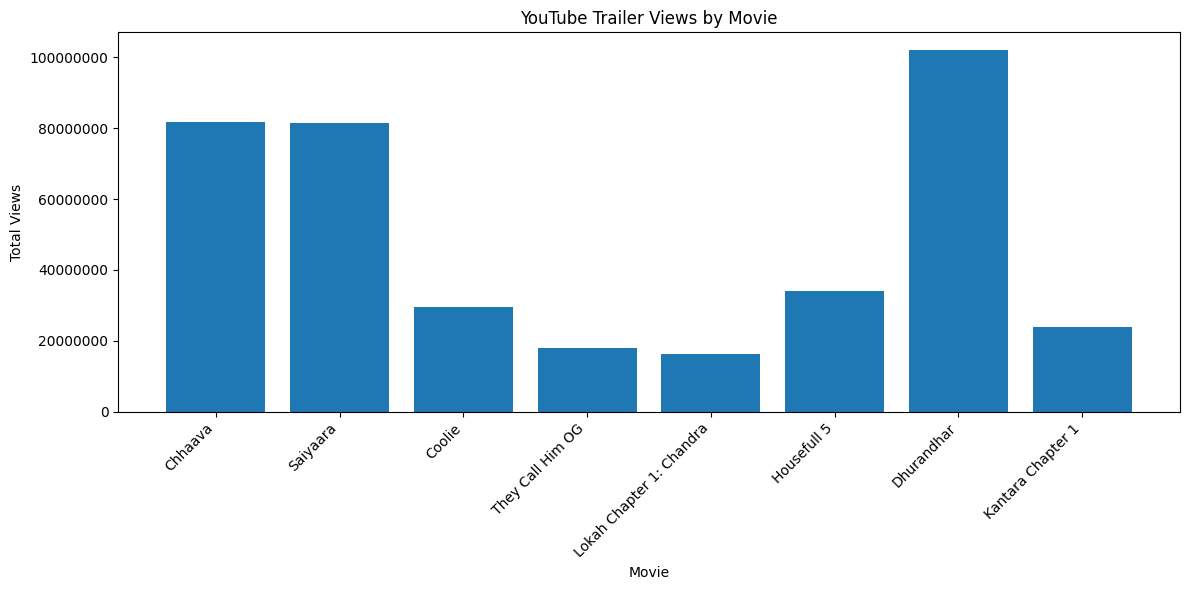

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

youtube_df = pd.read_csv("youtube_engagement_analysis.csv")

plt.figure(figsize=(12, 6))

plt.bar(
    youtube_df["Movie name"],
    youtube_df["Views"]
)

plt.title("YouTube Trailer Views by Movie")
plt.xlabel("Movie")
plt.ylabel("Total Views")

plt.xticks(rotation=45, ha="right")
plt.ticklabel_format(axis="y", style="plain")

plt.tight_layout()
plt.savefig("graph1_movie_views.png", dpi=300)
plt.show()


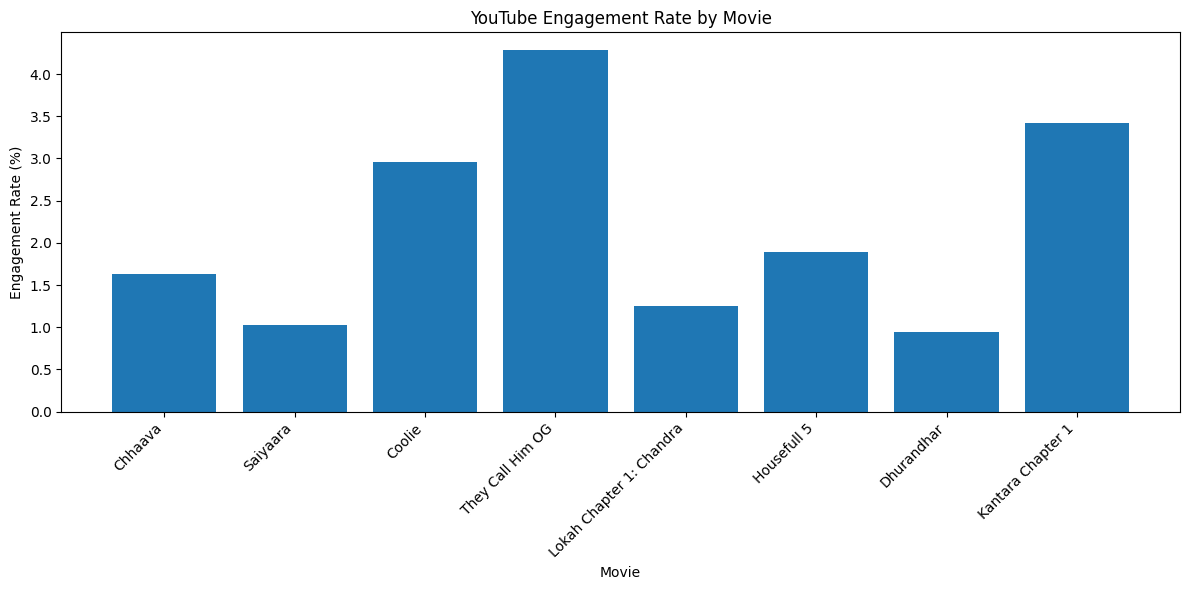

In [22]:

plt.figure(figsize=(12, 6))

plt.bar(
    youtube_df["Movie name"],
    youtube_df["Engagement Rate (%)"]
)

plt.title("YouTube Engagement Rate by Movie")
plt.xlabel("Movie")
plt.ylabel("Engagement Rate (%)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig("graph2_engagement_rate.png", dpi=300)
plt.show()


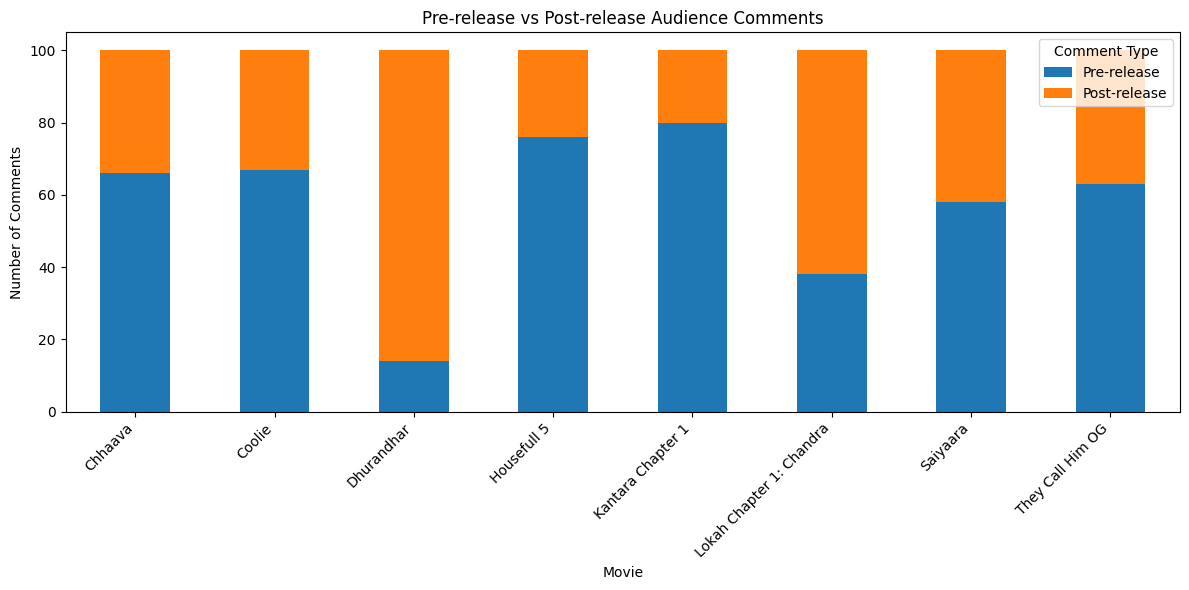

In [23]:

comments_df = pd.read_csv("cleaned_comments.csv")

comment_counts = pd.crosstab(
    comments_df["Movie name"],
    comments_df["Comment type"]
)

comment_counts = comment_counts.reindex(
    columns=["Pre-release", "Post-release"],
    fill_value=0
)

comment_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Pre-release vs Post-release Audience Comments")
plt.xlabel("Movie")
plt.ylabel("Number of Comments")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Comment Type")

plt.tight_layout()
plt.savefig("graph3_comment_comparison.png", dpi=300)
plt.show()


In [24]:

!pip install vaderSentiment


In [25]:

import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load comments
comments_df = pd.read_csv("cleaned_comments.csv")

# Create sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

# Handle missing comments
comments_df["Comment text"] = (
    comments_df["Comment text"].fillna("").astype(str)
)

# Calculate sentiment score
def analyse_sentiment(comment):

    scores = analyzer.polarity_scores(comment)

    compound = scores["compound"]

    if compound >= 0.05:
        sentiment = "Positive"

    elif compound <= -0.05:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    return pd.Series([
        sentiment,
        compound
    ])

# Apply sentiment analysis
comments_df[
    ["Sentiment", "Sentiment Score"]
] = comments_df["Comment text"].apply(
    analyse_sentiment
)

# Display sample results
print("SENTIMENT ANALYSIS SAMPLE")

display(
    comments_df[
        ["Movie name", "Comment text", "Sentiment", "Sentiment Score"]
    ].head(10)
)

# Overall sentiment distribution
print("\nOVERALL SENTIMENT DISTRIBUTION")

display(
    comments_df["Sentiment"].value_counts()
)

# Sentiment percentages
print("\nSENTIMENT PERCENTAGES")

display(
    (comments_df["Sentiment"].value_counts(normalize=True) * 100).round(2)
)

# Sentiment by movie
print("\nSENTIMENT BY MOVIE")

sentiment_by_movie = pd.crosstab(
    comments_df["Movie name"],
    comments_df["Sentiment"]
)

display(sentiment_by_movie)

# Sentiment percentages by movie
print("\nSENTIMENT PERCENTAGE BY MOVIE")

sentiment_percentage = (
    sentiment_by_movie.div(
        sentiment_by_movie.sum(axis=1),
        axis=0
    ) * 100
)

display(sentiment_percentage.round(2))

# Save results
comments_df.to_csv(
    "sentiment_analysis_results.csv",
    index=False
)

print("\nSentiment analysis completed successfully!")


SENTIMENT ANALYSIS SAMPLE


,Movie name,Comment text,Sentiment,Sentiment Score
0,Chhaava,CHHAAVA : He created River of Blood 🩸🩸\r\nMAHA...,Positive,0.4767
1,Chhaava,"Chhaavaa , Dhurandhar best movie role Akshay k...",Positive,0.6369
2,Chhaava,1:25 goosebumps. Can't believe that's Akshay K...,Neutral,0.0000
3,Chhaava,Who is here after DHURANDHAR 🥵\n\nRehman dakai...,Negative,-0.5994
4,Chhaava,Outstanding Acting By Vicky K Sir And Rehman S...,Positive,0.3818
5,Chhaava,हे हिंदवी स्वराज्य व्हावे ही श्रींची इच्छा 🔥🔥,Negative,-0.5859
6,Chhaava,Who is here after Raja shivaji teaser ❤😂,Positive,0.7269
7,Chhaava,Ritesh deshmukh ki movie Raja Shivaji ka tease...,Positive,0.7783
8,Chhaava,Akshay Khanna Acting. 🤫💥,Negative,-0.3612
9,Chhaava,"Movie released an year ago, but still Watching...",Neutral,0.0000



OVERALL SENTIMENT DISTRIBUTION


,count
Sentiment,
Positive,431
Negative,216
Neutral,153



SENTIMENT PERCENTAGES


,proportion
Sentiment,
Positive,53.87
Negative,27.00
Neutral,19.12



SENTIMENT BY MOVIE


Sentiment,Negative,Neutral,Positive
Movie name,,,
Chhaava,27,19,54
Coolie,42,15,43
Dhurandhar,28,22,50
Housefull 5,10,10,80
Kantara Chapter 1,27,21,52
Lokah Chapter 1: Chandra,25,21,54
Saiyaara,13,18,69
They Call Him OG,44,27,29



SENTIMENT PERCENTAGE BY MOVIE


Sentiment,Negative,Neutral,Positive
Movie name,,,
Chhaava,27.0,19.0,54.0
Coolie,42.0,15.0,43.0
Dhurandhar,28.0,22.0,50.0
Housefull 5,10.0,10.0,80.0
Kantara Chapter 1,27.0,21.0,52.0
Lokah Chapter 1: Chandra,25.0,21.0,54.0
Saiyaara,13.0,18.0,69.0
They Call Him OG,44.0,27.0,29.0



Sentiment analysis completed successfully!


In [26]:

!pip install pyspark datasets


In [28]:

from datasets import load_dataset
import pandas as pd

print("Downloading IMDb movie review dataset...")

# Use the full Hugging Face dataset name
imdb = load_dataset("stanfordnlp/imdb")

# Combine training and testing reviews
train_df = imdb["train"].to_pandas()
test_df = imdb["test"].to_pandas()

reviews_df = pd.concat(
    [train_df, test_df],
    ignore_index=True
)

# Rename columns
reviews_df = reviews_df.rename(columns={
    "text": "Review",
    "label": "Sentiment"
})

# Save dataset
reviews_df.to_json(
    "movie_reviews_50000.json",
    orient="records",
    lines=True
)

print("\nDATASET DOWNLOADED SUCCESSFULLY!")

print("Total reviews:", len(reviews_df))

print("\nDataset sample:")
display(reviews_df.head())

print("\nSentiment distribution:")
print(reviews_df["Sentiment"].value_counts())


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (3 outputs left out)

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]


DATASET DOWNLOADED SUCCESSFULLY!
Total reviews: 50000

Dataset sample:


,Review,Sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0



Sentiment distribution:
Sentiment
0    25000
1    25000
Name: count, dtype: int64


In [29]:

from pyspark.sql import SparkSession

# Create Spark session
spark = SparkSession.builder \
    .appName("Release Day Radar") \
    .master("local[*]") \
    .getOrCreate()

print("Apache Spark started successfully!")

print("Spark Version:", spark.version)


Apache Spark started successfully!
Spark Version: 4.0.5


In [30]:

# Load JSON dataset into Spark
spark_df = spark.read.json("movie_reviews_50000.json")

print("Dataset loaded into PySpark!")

print("\nDataset schema:")
spark_df.printSchema()

print("\nTotal records:")
print(spark_df.count())

print("\nFirst 10 reviews:")
spark_df.show(10, truncate=80)


Dataset loaded into PySpark!

Dataset schema:
root
 |-- Review: string (nullable = true)
 |-- Sentiment: long (nullable = true)


Total records:
50000

First 10 reviews:
+--------------------------------------------------------------------------------+---------+
|                                                                          Review|Sentiment|
+--------------------------------------------------------------------------------+---------+
|I rented I AM CURIOUS-YELLOW from my video store because of all the controver...|        0|
|"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't...|        0|
|If only to avoid making this type of film in the future. This film is interes...|        0|
|This film was probably inspired by Godard's Masculin, féminin and I urge you ...|        0|
|Oh, brother...after hearing about this ridiculous film for umpteen years all ...|        0|
|I would put this at the top of my list of films in the category of unwatchabl...|    

In [31]:

from pyspark.sql.functions import (
    col, when, length, avg, count
)

# Add sentiment labels
processed_df = spark_df.withColumn(
    "Sentiment_Label",
    when(col("Sentiment") == 1, "Positive")
    .otherwise("Negative")
)

# Calculate review length
processed_df = processed_df.withColumn(
    "Review_Length",
    length(col("Review"))
)

print("========== PROCESSED DATA ==========")

processed_df.show(10, truncate=80)

# Total reviews
print("\nTotal Reviews:", processed_df.count())

# Sentiment distribution
print("\nSENTIMENT DISTRIBUTION:")

processed_df.groupBy(
    "Sentiment_Label"
).agg(
    count("*").alias("Total Reviews")
).show()

# Average review length
print("\nAVERAGE REVIEW LENGTH:")

processed_df.groupBy(
    "Sentiment_Label"
).agg(
    avg("Review_Length").alias("Average Characters")
).show()

# Save processed dataset
processed_df.write.mode("overwrite").option(
    "header", True
).csv("pyspark_processed_reviews")

print("\nPySpark processing completed successfully!")


========== PROCESSED DATA ==========
+--------------------------------------------------------------------------------+---------+---------------+-------------+
|                                                                          Review|Sentiment|Sentiment_Label|Review_Length|
+--------------------------------------------------------------------------------+---------+---------------+-------------+
|I rented I AM CURIOUS-YELLOW from my video store because of all the controver...|        0|       Negative|         1640|
|"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't...|        0|       Negative|         1294|
|If only to avoid making this type of film in the future. This film is interes...|        0|       Negative|          528|
|This film was probably inspired by Godard's Masculin, féminin and I urge you ...|        0|       Negative|          706|
|Oh, brother...after hearing about this ridiculous film for umpteen years all ...|        0|       Neg

In [33]:

from google.colab import files

files.download("cleaned_youtube_data.csv")
files.download("cleaned_comments.csv")
files.download("sentiment_analysis_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:

import pandas as pd

files = [
    "cleaned_youtube_data.csv",
    "cleaned_comments.csv",
    "sentiment_analysis_results.csv"
]

for file in files:
    df = pd.read_csv(file)

    print("\nFILE:", file)
    print("COLUMNS:", df.columns.tolist())
    print("ROWS:", len(df))
    print(df.head(2))



FILE: cleaned_youtube_data.csv
COLUMNS: ['Movie name', 'Language', 'Release date', 'Video title', 'Channel', 'Video ID', 'Published date', 'Views', 'Likes', 'Comments', 'Retrieval timestamp']
ROWS: 8
  Movie name Language Release date  \
0    Chhaava    Hindi   2025-02-14   
1   Saiyaara    Hindi   2025-07-18   

                                         Video title        Channel  \
0  Chhaava | Official Trailer | Vicky K | Rashmik...  Maddock Films   
1  Saiyaara | Official Trailer | Ahaan Panday | A...            YRF   

      Video ID             Published date     Views    Likes  Comments  \
0  77vRyWNqZjM  2025-01-22 11:45:04+00:00  81728339  1238354     96159   
1  9r-tT5IN0vg  2025-07-08 05:30:04+00:00  81394643   801882     31615   

                Retrieval timestamp  
0  2026-11-26T09:59:08.636040+00:00  
1  2026-11-26T10:18:55.572639+00:00  

FILE: cleaned_comments.csv
COLUMNS: ['Movie name', 'Video ID', 'Comment text', 'Publication date', 'Comment likes', 'Comment type']


In [35]:

import pandas as pd

files = {
    "YouTube Data": "cleaned_youtube_data.csv",
    "Comments": "cleaned_comments.csv",
    "Sentiment Results": "sentiment_analysis_results.csv"
}

for name, filename in files.items():
    df = pd.read_csv(filename)

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    for column in df.columns:
        print(column)



YouTube Data
Movie name
Language
Release date
Video title
Channel
Video ID
Published date
Views
Likes
Comments
Retrieval timestamp

Comments
Movie name
Video ID
Comment text
Publication date
Comment likes
Comment type

Sentiment Results
Movie name
Video ID
Comment text
Publication date
Comment likes
Comment type
Sentiment
Sentiment Score


In [36]:

import pandas as pd

# Load the three CSV files
youtube = pd.read_csv("cleaned_youtube_data.csv")
comments = pd.read_csv("cleaned_comments.csv")
sentiment = pd.read_csv("sentiment_analysis_results.csv")

# -------------------------------
# 1. Prepare YouTube statistics
# -------------------------------

youtube_sql = youtube.copy()

# Match movie names with MySQL movie IDs
movie_ids = {
    "Chhaava": 1,
    "Saiyaara": 2,
    "Housefull 5": 3,
    "Dhurandhar": 4,
    "Kantara Chapter 1": 5,
    "Coolie": 6,
    "They Call Him OG": 7,
    "Lokah Chapter 1: Chandra": 8
}

youtube_sql["movie_id"] = youtube_sql["Movie name"].map(movie_ids)

youtube_sql = youtube_sql.rename(columns={
    "Video ID": "video_id",
    "Video title": "video_title",
    "Channel": "channel_name",
    "Views": "views",
    "Likes": "likes",
    "Comments": "comments",
    "Retrieval timestamp": "retrieval_date"
})

youtube_sql["engagement_rate"] = (
    (youtube_sql["likes"] + youtube_sql["comments"])
    / youtube_sql["views"] * 100
)

youtube_sql["retrieval_date"] = pd.to_datetime(
    youtube_sql["retrieval_date"]
).dt.date

youtube_sql = youtube_sql[[
    "movie_id",
    "video_id",
    "video_title",
    "channel_name",
    "views",
    "likes",
    "comments",
    "engagement_rate",
    "retrieval_date"
]]

youtube_sql.to_csv("mysql_youtube_import.csv", index=False)

# -------------------------------
# 2. Prepare comments
# -------------------------------

comments_sql = comments.copy()

comments_sql["movie_id"] = comments_sql["Movie name"].map(movie_ids)

comments_sql = comments_sql.rename(columns={
    "Comment text": "comment_text",
    "Publication date": "comment_date",
    "Comment type": "release_period"
})

comments_sql["comment_date"] = pd.to_datetime(
    comments_sql["comment_date"]
).dt.date

comments_sql = comments_sql[[
    "movie_id",
    "comment_text",
    "comment_date",
    "release_period"
]]

comments_sql.to_csv("mysql_comments_import.csv", index=False)

# -------------------------------
# 3. Prepare sentiment
# -------------------------------

sentiment_sql = sentiment.copy()

sentiment_sql["movie_id"] = sentiment_sql["Movie name"].map(movie_ids)

sentiment_sql = sentiment_sql.rename(columns={
    "Comment text": "comment_text",
    "Sentiment": "sentiment_label",
    "Sentiment Score": "sentiment_score"
})

sentiment_sql = sentiment_sql[[
    "movie_id",
    "comment_text",
    "sentiment_label",
    "sentiment_score"
]]

sentiment_sql.to_csv("mysql_sentiment_import.csv", index=False)

print("MySQL import files created successfully!")
print("YouTube records:", len(youtube_sql))
print("Comment records:", len(comments_sql))
print("Sentiment records:", len(sentiment_sql))


MySQL import files created successfully!
YouTube records: 8
Comment records: 800
Sentiment records: 800


In [37]:

from google.colab import files

files.download("mysql_youtube_import.csv")
files.download("mysql_comments_import.csv")
files.download("mysql_sentiment_import.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import pandas as pd

# Read the prepared comments file
df = pd.read_csv("mysql_comments_import.csv", encoding="utf-8")
print("Rows before:", len(df))

# Remove characters MySQL Workbench cannot read (emojis, special symbols)
df["comment_text"] = (
    df["comment_text"]
    .astype(str)
    .str.encode("ascii", errors="ignore")
    .str.decode("ascii")
    .str.replace(r"[\r\n]+", " ", regex=True)
    .str.strip()
)

# Save as a new file (original stays unchanged)
df.to_csv("mysql_comments_import_safe.csv", index=False, encoding="utf-8")

print("Rows after:", len(df))
print(df.columns.tolist())
print(df.head())

# Download to your computer
from google.colab import files
files.download("mysql_comments_import_safe.csv")

Rows before: 800
Rows after: 800
['movie_id', 'comment_text', 'comment_date', 'release_period']
   movie_id                                       comment_text comment_date  \
0         1  CHHAAVA : He created River of Blood  MAHAVATAR...   2026-09-24   
1         1  Chhaavaa , Dhurandhar best movie role Akshay k...   2025-12-13   
2         1  1:25 goosebumps. Can't believe that's Akshay K...   2025-01-22   
3         1  Who is here after DHURANDHAR  Rehman dakait pe...   2025-12-10   
4         1  Outstanding Acting By Vicky K Sir And Rehman S...   2025-01-22   

  release_period  
0   Post-release  
1   Post-release  
2    Pre-release  
3   Post-release  
4    Pre-release  


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
import pandas as pd

df = pd.read_csv("mysql_comments_import_safe.csv")

print(df["movie_id"].value_counts().sort_index())
print()
print(df.iloc[97:104])
print()
print(df.dtypes)
print()
print("Empty comments:", (df["comment_text"].str.strip() == "").sum())
print("Missing values:")
print(df.isna().sum())

movie_id
1    100
2    100
3    100
4    100
5    100
6    100
7    100
8    100
Name: count, dtype: int64

     movie_id                                       comment_text comment_date  \
97          1                                          ,      ,.   2025-01-26   
98          1                                                NaN   2025-01-28   
99          1  This is not just a movie, these are the sacrif...   2025-02-16   
100         2  this debut is gonna be remembered forever and ...          NaN   
101         2  honestly saying that this movie deserve the ti...          NaN   
102         2  People made this thing blockbuster on opening ...          NaN   
103         2  Her anger was so real in that scene. She will ...          NaN   

    release_period  
97     Pre-release  
98     Pre-release  
99    Post-release  
100    Pre-release  
101    Pre-release  
102   Post-release  
103   Post-release  

movie_id           int64
comment_text      object
comment_date      object

In [40]:
import pandas as pd

for name in ["cleaned_comments.csv", "mysql_comments_import.csv", "sentiment_analysis_results.csv"]:
    d = pd.read_csv(name)
    print("=====", name, "=====")
    print("Rows:", len(d))
    print("Columns:", d.columns.tolist())
    for col in d.columns:
        if "date" in col.lower():
            print(f"Missing in '{col}':", d[col].isna().sum())
    print()

d = pd.read_csv("cleaned_comments.csv")
print(d.head(3))
print(d.groupby("movie_id" if "movie_id" in d.columns else d.columns[0]).size())

===== cleaned_comments.csv =====
Rows: 800
Columns: ['Movie name', 'Video ID', 'Comment text', 'Publication date', 'Comment likes', 'Comment type']
Missing in 'Publication date': 700

===== mysql_comments_import.csv =====
Rows: 800
Columns: ['movie_id', 'comment_text', 'comment_date', 'release_period']
Missing in 'comment_date': 700

===== sentiment_analysis_results.csv =====
Rows: 800
Columns: ['Movie name', 'Video ID', 'Comment text', 'Publication date', 'Comment likes', 'Comment type', 'Sentiment', 'Sentiment Score']
Missing in 'Publication date': 700

  Movie name Video ID                                       Comment text  \
0    Chhaava      NaN  CHHAAVA : He created River of Blood 🩸🩸\r\nMAHA...   
1    Chhaava      NaN  Chhaavaa , Dhurandhar best movie role Akshay k...   
2    Chhaava      NaN  1:25 goosebumps. Can't believe that's Akshay K...   

            Publication date  Comment likes  Comment type  
0  2026-09-24 16:35:38+00:00            221  Post-release  
1  2025-12-13

In [41]:
import pandas as pd

df = pd.read_csv("mysql_comments_import.csv", encoding="utf-8")
print("Rows:", len(df))

# Clean text: remove characters MySQL Workbench cannot read
text = (
    df["comment_text"]
    .fillna("")
    .astype(str)
    .str.encode("ascii", errors="ignore")
    .str.decode("ascii")
    .str.replace(r"[\r\n]+", " ", regex=True)
    .str.strip()
)

# Comments that were only emojis / regional-language text become empty,
# so give them a placeholder to keep all 800 rows
placeholder = "[emoji or non-English text only]"
print("Comments needing placeholder:", (text == "").sum())
text = text.replace("", placeholder)
df["comment_text"] = text

# Drop the date column (700 of 800 are blank)
df = df[["movie_id", "comment_text", "release_period"]]

df.to_csv("mysql_comments_import_v2.csv", index=False, encoding="utf-8")

print(df.columns.tolist())
print(df["release_period"].value_counts())
print(df.isna().sum())
print(df.head())

from google.colab import files
files.download("mysql_comments_import_v2.csv")

Rows: 800
Comments needing placeholder: 29
['movie_id', 'comment_text', 'release_period']
release_period
Pre-release     462
Post-release    338
Name: count, dtype: int64
movie_id          0
comment_text      0
release_period    0
dtype: int64
   movie_id                                       comment_text release_period
0         1  CHHAAVA : He created River of Blood  MAHAVATAR...   Post-release
1         1  Chhaavaa , Dhurandhar best movie role Akshay k...   Post-release
2         1  1:25 goosebumps. Can't believe that's Akshay K...    Pre-release
3         1  Who is here after DHURANDHAR  Rehman dakait pe...   Post-release
4         1  Outstanding Acting By Vicky K Sir And Rehman S...    Pre-release


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import pandas as pd

df = pd.read_csv("mysql_comments_import_v2.csv", encoding="utf-8")
df["row_number"] = df.index + 1   # position in the file (1 to 800)
df["length"] = df["comment_text"].str.len()

flags = (
    df["comment_text"].str.contains(r'\\', regex=True)
    | df["comment_text"].str.contains('"', regex=False)
    | df["comment_text"].str.contains("'", regex=False)
    | (df["length"] > 1000)
)

print("Suspicious rows:", flags.sum())
print(df.loc[flags, ["row_number", "movie_id", "length", "comment_text"]].head(30).to_string())
print()
print(df.groupby("movie_id").size())

Suspicious rows: 108
     row_number  movie_id  length                                                                                                                                                                                                                                                                                                                                                                                                 comment_text
0             1         1      76                                                                                                                                                                                                                                                                                                                                 CHHAAVA : He created River of Blood  MAHAVATAR : He'll create Ocean of Blood
2             3         1      51                                                                                    

In [43]:
import pandas as pd

df = pd.read_csv("mysql_comments_import_v2.csv", encoding="utf-8")
print("Rows:", len(df))

def esc(s):
    s = str(s).replace("\\", "\\\\").replace("'", "\\'")
    return s

lines = []
lines.append("USE release_day_radar;")
lines.append("DELETE FROM youtube_comments WHERE comment_id > 0;")
lines.append("ALTER TABLE youtube_comments AUTO_INCREMENT = 1;")

batch_size = 100
for start in range(0, len(df), batch_size):
    chunk = df.iloc[start:start + batch_size]
    values = []
    for i, row in chunk.iterrows():
        values.append(
            f"({i + 1}, {int(row['movie_id'])}, '{esc(row['comment_text'])}', '{esc(row['release_period'])}')"
        )
    lines.append(
        "INSERT INTO youtube_comments (comment_id, movie_id, comment_text, release_period) VALUES\n"
        + ",\n".join(values) + ";"
    )

lines.append("SELECT COUNT(*) AS total_comments FROM youtube_comments;")

with open("insert_comments.sql", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("Script written with", len(df), "rows")

from google.colab import files
files.download("insert_comments.sql")

Rows: 800
Script written with 800 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import pandas as pd

sent = pd.read_csv("sentiment_analysis_results.csv")
imp = pd.read_csv("mysql_comments_import.csv")

print("Sentiment file rows:", len(sent))
print("Columns:")
for c in sent.columns:
    print("  -", c)
print()
print(sent.head(3).T)
print()

# Check the movie order matches the comments import file
movie_map = {"Chhaava":1, "Saiyaara":2, "Housefull 5":3, "Dhurandhar":4,
             "Kantara Chapter 1":5, "Coolie":6, "They Call Him OG":7,
             "Lokah Chapter 1: Chandra":8}
print("Movie names in sentiment file:", sent["Movie name"].unique().tolist())
print("Movie order identical:", (sent["Movie name"].map(movie_map).values == imp["movie_id"].values).all())

# Check the first 40 characters of each comment match row by row
a = sent["Comment text"].fillna("").astype(str).str.encode("ascii", errors="ignore").str.decode("ascii").str.strip().str[:40]
b = imp["comment_text"].fillna("").astype(str).str.encode("ascii", errors="ignore").str.decode("ascii").str.strip().str[:40]
print("Comment text matches row by row:", (a.values == b.values).sum(), "of", len(a))

Sentiment file rows: 800
Columns:
  - Movie name
  - Video ID
  - Comment text
  - Publication date
  - Comment likes
  - Comment type
  - Sentiment
  - Sentiment Score

                                                                  0  \
Movie name                                                  Chhaava   
Video ID                                                        NaN   
Comment text      CHHAAVA : He created River of Blood 🩸🩸\r\nMAHA...   
Publication date                          2026-09-24 16:35:38+00:00   
Comment likes                                                   221   
Comment type                                           Post-release   
Sentiment                                                  Positive   
Sentiment Score                                              0.4767   

                                                                  1  \
Movie name                                                  Chhaava   
Video ID                                        

In [45]:
import pandas as pd
import re

sent = pd.read_csv("sentiment_analysis_results.csv")
imp = pd.read_csv("mysql_comments_import_v2.csv", encoding="utf-8")
print("Rows:", len(sent), len(imp))

# Check 1: each movie name maps to exactly one movie_id, in the same row order
check = pd.DataFrame({"name": sent["Movie name"], "movie_id": imp["movie_id"]})
print(check.drop_duplicates().to_string(index=False))
one_to_one = check.drop_duplicates().groupby("name").size().max() == 1

# Check 2: comment text matches row by row (letters and digits only)
def norm(s):
    s = str(s).encode("ascii", errors="ignore").decode("ascii")
    return re.sub(r"[^A-Za-z0-9]", "", s)[:30]

a = sent["Comment text"].fillna("").map(norm)
b = imp["comment_text"].fillna("").map(norm)
placeholder_rows = b.str.startswith("emojiornonEnglishtext")
text_ok = ((a == b) | placeholder_rows | (a == "")).sum()
print("Text matches:", text_ok, "of", len(a))

print("Sentiment labels:", sent["Sentiment"].value_counts().to_dict())
print("Missing in Sentiment / Score:", sent["Sentiment"].isna().sum(), sent["Sentiment Score"].isna().sum())

if one_to_one and text_ok == 800:
    lines = ["USE release_day_radar;",
             "DELETE FROM comment_sentiment WHERE sentiment_id > 0;",
             "ALTER TABLE comment_sentiment AUTO_INCREMENT = 1;"]
    for start in range(0, 800, 100):
        vals = []
        for i in range(start, start + 100):
            label = str(sent.loc[i, "Sentiment"]).replace("'", "''")
            score = float(sent.loc[i, "Sentiment Score"])
            vals.append(f"({i + 1}, '{label}', {score})")
        lines.append("INSERT INTO comment_sentiment (comment_id, sentiment_label, sentiment_score) VALUES\n"
                     + ",\n".join(vals) + ";")
    lines.append("SELECT COUNT(*) AS total_sentiment FROM comment_sentiment;")
    with open("insert_sentiment.sql", "w", encoding="utf-8") as f:
        f.write("\n".join(lines))
    print("\nALL CHECKS PASSED - script created")
    from google.colab import files
    files.download("insert_sentiment.sql")
else:
    print("\nCHECK FAILED - no script created")

Rows: 800 800
                    name  movie_id
                 Chhaava         1
                Saiyaara         2
                  Coolie         6
        They Call Him OG         7
Lokah Chapter 1: Chandra         8
             Housefull 5         3
              Dhurandhar         4
       Kantara Chapter 1         5
Text matches: 800 of 800
Sentiment labels: {'Positive': 431, 'Negative': 216, 'Neutral': 153}
Missing in Sentiment / Score: 0 0

ALL CHECKS PASSED - script created


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>